# A Comparative Study of Imbalanced Data Handling Techniques for Detecting Fraudulent Credit Card Transactions

**Import Libararies**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the Dataset**


In [ ]:
# Download the Kaggle dataset and place the CSV in the same folder as this notebook
df = pd.read_csv("credit_card_imbalance_dataset.csv")

**Dataset Overview**

In [ ]:
df.shape

(284807, 31)

In [ ]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.dtypes

,0
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


**Data Preprocessing**

In [ ]:
df.isna().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.duplicated().sum()

np.int64(1081)

In [ ]:
df[df.duplicated()].head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [ ]:
df[df.duplicated()].shape

(1081, 31)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(283726, 31)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


**Data Type Optimisation**


Data type optimisation was considered, however, the existing data types were kept.


**Class Imbalance Analysis**

In [ ]:
df['Class'].value_counts()
df['Class'].value_counts(normalize=True) * 100

,proportion
Class,
0,99.83329
1,0.16671


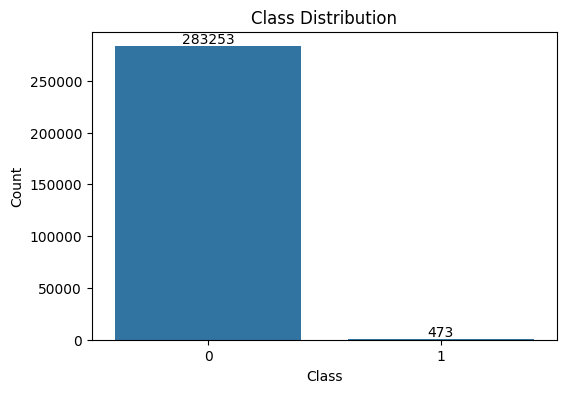

In [ ]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(x='Class', data=df)

plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center',
                va='bottom')

plt.show()

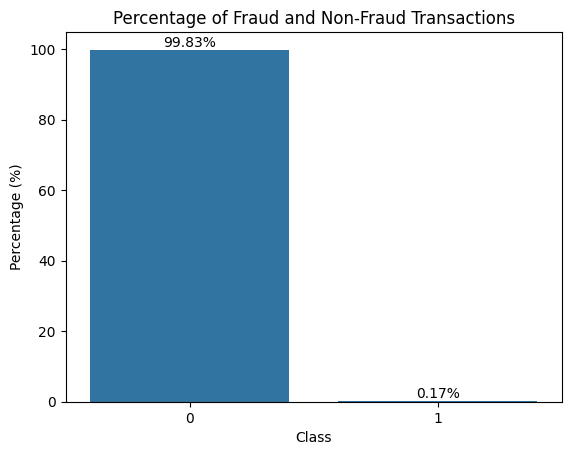

In [ ]:
# Calculate class percentages
class_percent = df['Class'].value_counts(normalize=True).sort_index() * 100

# Create the bar chart
ax = sns.barplot(x=class_percent.index,
                 y=class_percent.values)

# Add title and labels
plt.title('Percentage of Fraud and Non-Fraud Transactions')
plt.xlabel('Class')
plt.ylabel('Percentage (%)')

# Add percentage labels on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width()/2,
                 p.get_height()),
                ha='center',
                va='bottom')

plt.show()

# **Statistical Analysis of Class Distribution**

To statistically analyse the dataset distribution, a two-sided exact binomial test and Mann–Whitney U test were applied.

In [ ]:
from scipy.stats import binomtest

# Count fraud and legitimate transactions
fraud_count = (df['Class'] == 1).sum()
legitimate_count = (df['Class'] == 0).sum()
total = len(df)

# Two-sided exact binomial test
result = binomtest(
    k=fraud_count,
    n=total,
    p=0.5,
    alternative='two-sided'
)

print("Legitimate transactions:", legitimate_count)
print("Fraudulent transactions:", fraud_count)
print("Fraud proportion:", fraud_count / total)
print("P-value:", result.pvalue)

Legitimate transactions: 283253
Fraudulent transactions: 473
Fraud proportion: 0.001667101358352777
P-value: 0.0


In [ ]:
from scipy.stats import mannwhitneyu

# Separate transaction amounts by class
legitimate_amount = df[df['Class'] == 0]['Amount']
fraud_amount = df[df['Class'] == 1]['Amount']

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    fraud_amount,
    legitimate_amount,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", u_stat)
print("P-value:", p_value)

# Useful descriptive values
print("Median Amount - Legitimate:", legitimate_amount.median())
print("Median Amount - Fraud:", fraud_amount.median())

Mann-Whitney U statistic: 59517129.5
P-value: 2.68609023836721e-05
Median Amount - Legitimate: 22.0
Median Amount - Fraud: 9.82


**Exploratory Data Analysis (EDA)**

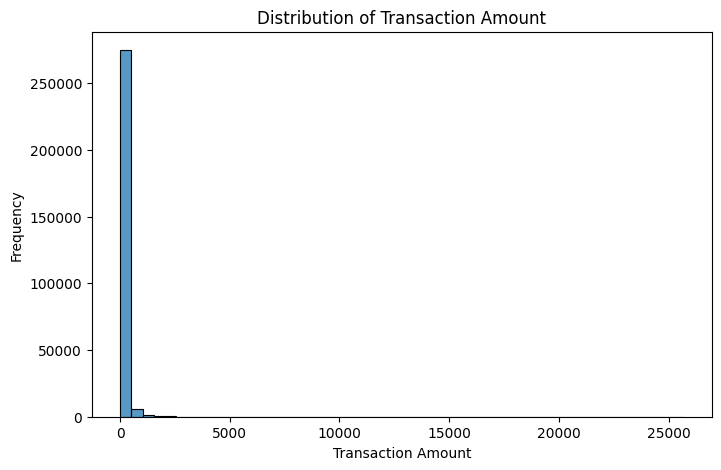

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Amount'], bins=50)

plt.title('Distribution of Transaction Amount')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

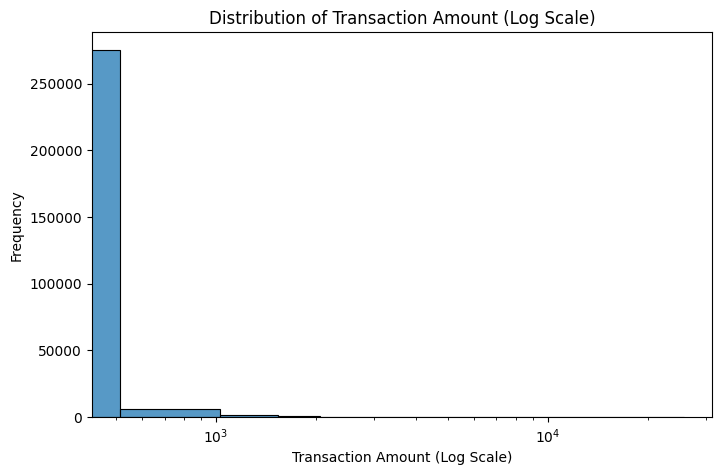

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Amount'], bins=50)

plt.xscale('log')

plt.title('Distribution of Transaction Amount (Log Scale)')
plt.xlabel('Transaction Amount (Log Scale)')
plt.ylabel('Frequency')

plt.show()

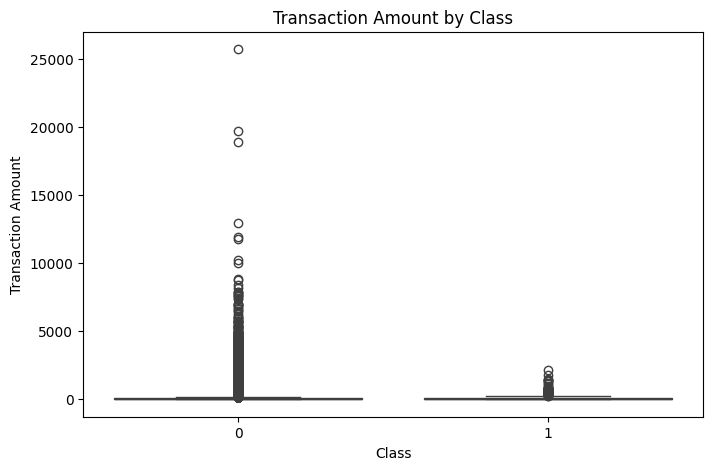

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Class', y='Amount', data=df)

plt.title('Transaction Amount by Class')
plt.xlabel('Class')
plt.ylabel('Transaction Amount')

plt.show()

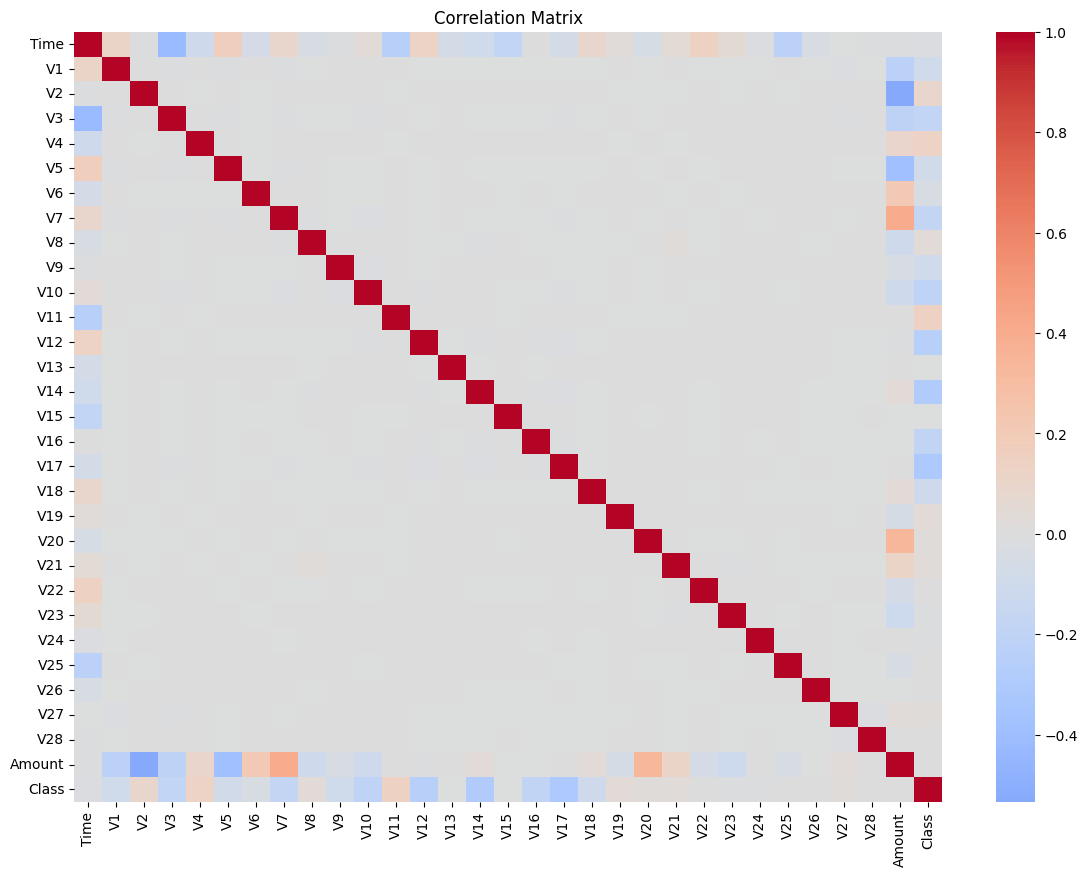

In [ ]:
plt.figure(figsize=(14,10))

corr = df.corr()

sns.heatmap(corr,
            cmap='coolwarm',
            center=0)

plt.title('Correlation Matrix')

plt.show()

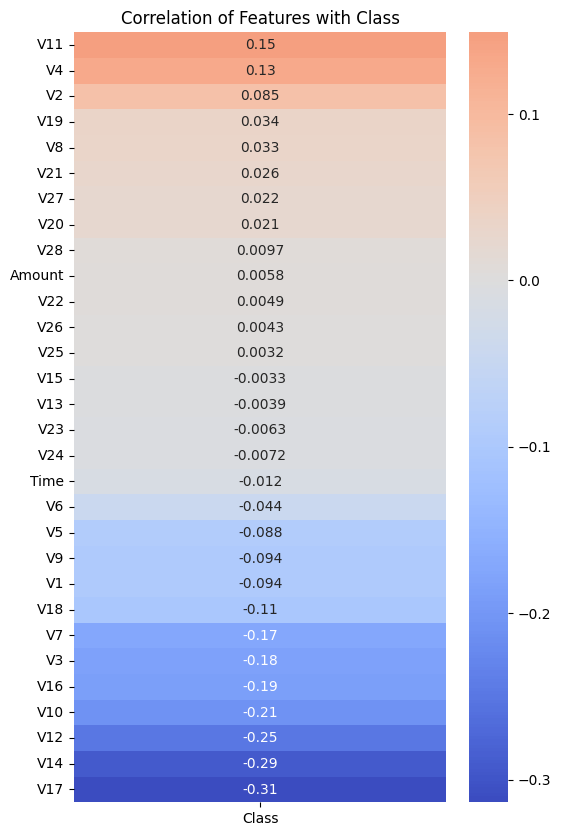

In [ ]:
plt.figure(figsize=(6,10))

corr_class = df.corr()[['Class']].drop('Class')
corr_class = corr_class.sort_values(by='Class', ascending=False)

sns.heatmap(corr_class,
            annot=True,
            cmap='coolwarm',
            center=0)

plt.title('Correlation of Features with Class')

plt.show()

**Normality Analysis**

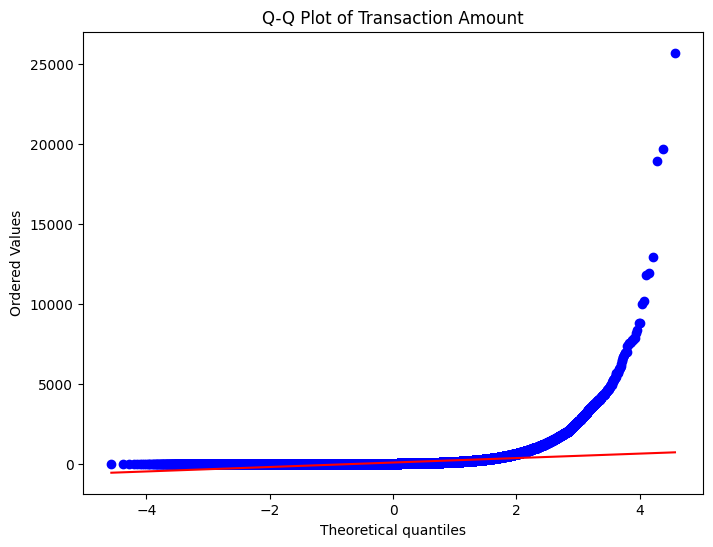

In [ ]:
from scipy import stats

plt.figure(figsize=(8,6))

stats.probplot(df['Amount'], dist="norm", plot=plt)

plt.title('Q-Q Plot of Transaction Amount')

plt.show()

In [ ]:
print("Skewness:", df['Amount'].skew())
print("Kurtosis:", df['Amount'].kurt())

Skewness: 16.978803370060476
Kurtosis: 844.471319490649


**Feature Selection (X and y)**

In [ ]:
# Features (Independent Variables)
X = df.drop('Class', axis=1)

# Target Variable (Dependent Variable)
y = df['Class']

In [ ]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (283726, 30)
Shape of y: (283726,)


**Train-Test Split**


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (226980, 30)
X_test : (56746, 30)
y_train: (226980,)
y_test : (56746,)


In [ ]:
print("Training Set (%)")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Set (%)")
print(y_test.value_counts(normalize=True) * 100)

Training Set (%)
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

Testing Set (%)
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


**Feature Scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the testing data
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (226980, 30)
X_test_scaled shape : (56746, 30)


**Baseline Logistic Regression (Without Class Balancing)**


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lr_model = LogisticRegression(random_state=42)

In [ ]:
lr_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [ ]:
y_pred = lr_model.predict(X_test_scaled)

In [ ]:
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

In [ ]:
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print("PR-AUC   :", average_precision_score(y_test, y_prob))
print("Accuracy :", accuracy_score(y_test, y_pred))

Precision: 0.8461538461538461
Recall   : 0.5789473684210527
F1-score : 0.6875
ROC-AUC  : 0.9560466717268892
PR-AUC   : 0.6919665484964556
Accuracy : 0.9991188806259472


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



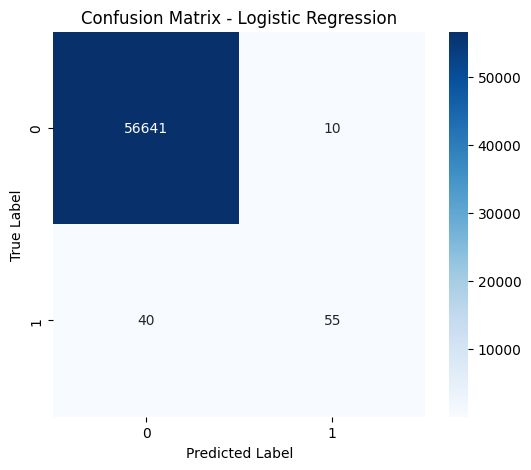

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

**Random Oversampling (Logistic Regression)**

In [ ]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train_scaled, y_train)

In [ ]:
print(y_train_ros.value_counts())

print("\nPercentage:")

print(y_train_ros.value_counts(normalize=True) * 100)

Class
0    226602
1    226602
Name: count, dtype: int64

Percentage:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
# Create Logistic Regression model
lr_ros = LogisticRegression(random_state=42)

# Train the model
lr_ros.fit(X_train_ros, y_train_ros)

# Predict class labels
y_pred_ros = lr_ros.predict(X_test_scaled)

# Predict probabilities
y_prob_ros = lr_ros.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_ros))
print("Recall   :", recall_score(y_test, y_pred_ros))
print("F1-score :", f1_score(y_test, y_pred_ros))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_ros))
print("PR-AUC   :", average_precision_score(y_test, y_prob_ros))
print("Accuracy :", accuracy_score(y_test, y_pred_ros))

print(classification_report(y_test, y_pred_ros))

Precision: 0.05653950953678474
Recall   : 0.8736842105263158
F1-score : 0.10620601407549585
ROC-AUC  : 0.9659571206528615
PR-AUC   : 0.6689355881144186
Accuracy : 0.9753815246889649
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



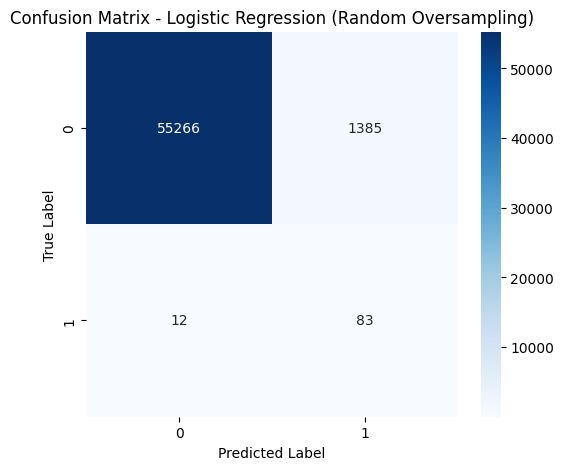

In [ ]:
cm_ros = confusion_matrix(y_test, y_pred_ros)

plt.figure(figsize=(6,5))
sns.heatmap(cm_ros,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title('Confusion Matrix - Logistic Regression (Random Oversampling)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

**Random Undersampling (Logistic Regression)**


In [ ]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)
print(y_train_rus.value_counts())

print("\nPercentage:")

print(y_train_rus.value_counts(normalize=True) * 100)

Class
0    378
1    378
Name: count, dtype: int64

Percentage:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
lr_rus = LogisticRegression(random_state=42)
lr_rus.fit(X_train_rus, y_train_rus)
y_pred_rus = lr_rus.predict(X_test_scaled)
y_prob_rus = lr_rus.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rus))
print("Recall   :", recall_score(y_test, y_pred_rus))
print("F1-score :", f1_score(y_test, y_pred_rus))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rus))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rus))
print("Accuracy :", accuracy_score(y_test, y_pred_rus))

print(classification_report(y_test, y_pred_rus))

Precision: 0.050425273390036454
Recall   : 0.8736842105263158
F1-score : 0.09534750143595634
ROC-AUC  : 0.9571076461696685
PR-AUC   : 0.5895570356891764
Accuracy : 0.9722447397173369
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.98     56746



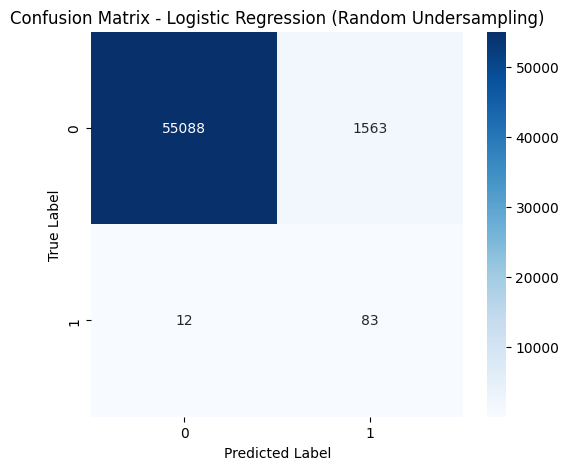

In [ ]:
cm_rus = confusion_matrix(y_test, y_pred_rus)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rus,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title('Confusion Matrix - Logistic Regression (Random Undersampling)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

**SMOTE (Logistic Regression)**

In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print(y_train_smote.value_counts())

print("\nPercentage:")

print(y_train_smote.value_counts(normalize=True) * 100)

Class
0    226602
1    226602
Name: count, dtype: int64

Percentage:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
lr_smote = LogisticRegression(random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = lr_smote.predict(X_test_scaled)
y_prob_smote = lr_smote.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_smote))
print("Recall   :", recall_score(y_test, y_pred_smote))
print("F1-score :", f1_score(y_test, y_pred_smote))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_smote))
print("PR-AUC   :", average_precision_score(y_test, y_prob_smote))
print("Accuracy :", accuracy_score(y_test, y_pred_smote))

print(classification_report(y_test, y_pred_smote))

Precision: 0.053035143769968054
Recall   : 0.8736842105263158
F1-score : 0.1
ROC-AUC  : 0.9626184886409772
PR-AUC   : 0.6750409387333339
Accuracy : 0.9736721531033025
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



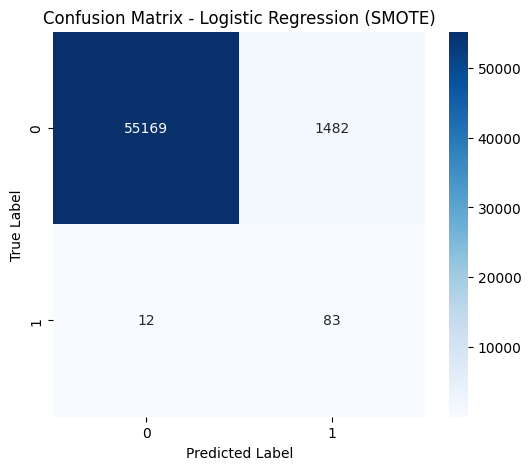

In [ ]:
cm_smote = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_smote,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title('Confusion Matrix - Logistic Regression (SMOTE)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

**Model Performance Comparison**

# **Logistic Regression Results**

| Metric    |   Baseline | Random Oversampling | Random Undersampling |      SMOTE |
| --------- | ---------: | ------------------: | -------------------: | ---------: |
| Precision | **84.61%** |               5.65% |                5.04% |      5.30% |
| Recall    |     57.89% |          **87.37%** |           **87.37%** | **87.37%** |
| F1-score  | **68.75%** |              10.62% |                9.53% |     10.00% |
| ROC-AUC   |      0.956 |           **0.966** |                0.957 |      0.962 |
| PR-AUC    |  **0.692** |               0.669 |                0.590 |      0.675 |
| Accuracy  | **99.91%** |              97.54% |               97.22% |     97.37% |


**Confusion Matrix Comparison**

| Model                |         TN |     FP |     FN |     TP |
| -------------------- | ---------: | -----: | -----: | -----: |
| Baseline             | **56,641** | **10** |     40 |     55 |
| Random Oversampling  |     55,266 |  1,385 | **12** | **83** |
| Random Undersampling |     55,088 |  1,563 | **12** | **83** |
| SMOTE                |     55,169 |  1,482 | **12** | **83** |


**Training Dataset Size**

| Model                | Training Samples |
| -------------------- | ---------------: |
| Baseline             |          226,980 |
| Random Oversampling  |          453,204 |
| Random Undersampling |              756 |
| SMOTE                |          453,204 |


**Baseline Random Forest (Without Class Balancing)**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [ ]:
RandomForestClassifier?

In [ ]:
rf_model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [ ]:
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1-score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf))
print("Accuracy :", accuracy_score(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

Precision: 0.971830985915493
Recall   : 0.7263157894736842
F1-score : 0.8313253012048193
ROC-AUC  : 0.9239441121028197
PR-AUC   : 0.7876128638875491
Accuracy : 0.9995065731505305
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.92     56746
weighted avg       1.00      1.00      1.00     56746



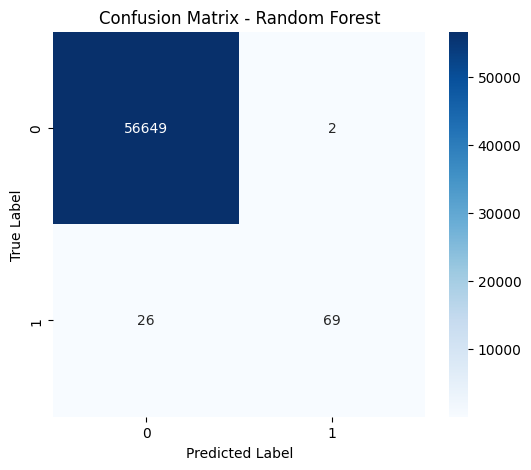

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**Random Oversampling (Random Forest)**

In [ ]:
rf_ros = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_ros.fit(X_train_ros, y_train_ros)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_ros = rf_ros.predict(X_test_scaled)
y_prob_rf_ros = rf_ros.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_ros))
print("Recall   :", recall_score(y_test, y_pred_rf_ros))
print("F1-score :", f1_score(y_test, y_pred_rf_ros))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_ros))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_ros))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_ros))

print(classification_report(y_test, y_pred_rf_ros))

Precision: 0.9583333333333334
Recall   : 0.7263157894736842
F1-score : 0.8263473053892215
ROC-AUC  : 0.9291467888800216
PR-AUC   : 0.8023827974994455
Accuracy : 0.9994889507630493
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



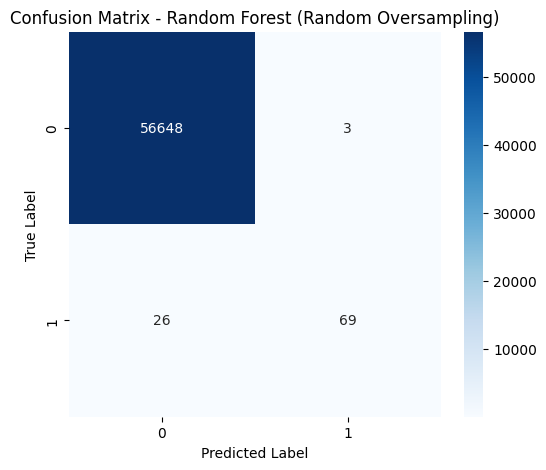

In [ ]:
cm_rf_ros = confusion_matrix(y_test, y_pred_rf_ros)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf_ros,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Random Forest (Random Oversampling)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**Random Undersampling (Random Forest)**

In [ ]:
rf_rus = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_rus.fit(X_train_rus, y_train_rus)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_rus = rf_rus.predict(X_test_scaled)
y_prob_rf_rus = rf_rus.predict_proba(X_test_scaled)[:, 1]


In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_rus))
print("Recall   :", recall_score(y_test, y_pred_rf_rus))
print("F1-score :", f1_score(y_test, y_pred_rf_rus))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_rus))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_rus))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_rus))

print(classification_report(y_test, y_pred_rf_rus))

Precision: 0.08478038815117467
Recall   : 0.8736842105263158
F1-score : 0.15456238361266295
ROC-AUC  : 0.9766969320000854
PR-AUC   : 0.6982843966808189
Accuracy : 0.9839988721672012
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.08      0.87      0.15        95

    accuracy                           0.98     56746
   macro avg       0.54      0.93      0.57     56746
weighted avg       1.00      0.98      0.99     56746



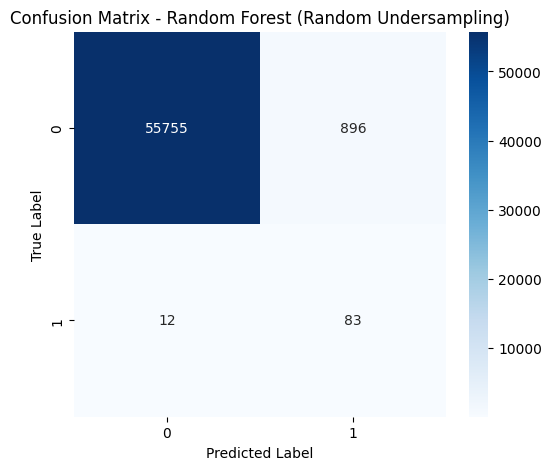

In [ ]:
cm_rf_rus = confusion_matrix(y_test, y_pred_rf_rus)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf_rus,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Random Forest (Random Undersampling)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**SMOTE (Random Forest)**

In [ ]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_smote = rf_smote.predict(X_test_scaled)
y_prob_rf_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_smote))
print("Recall   :", recall_score(y_test, y_pred_rf_smote))
print("F1-score :", f1_score(y_test, y_pred_rf_smote))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_smote))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_smote))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_smote))

print(classification_report(y_test, y_pred_rf_smote))

Precision: 0.9125
Recall   : 0.7684210526315789
F1-score : 0.8342857142857143
ROC-AUC  : 0.9694220104815354
PR-AUC   : 0.8114822514189992
Accuracy : 0.9994889507630493
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.77      0.83        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



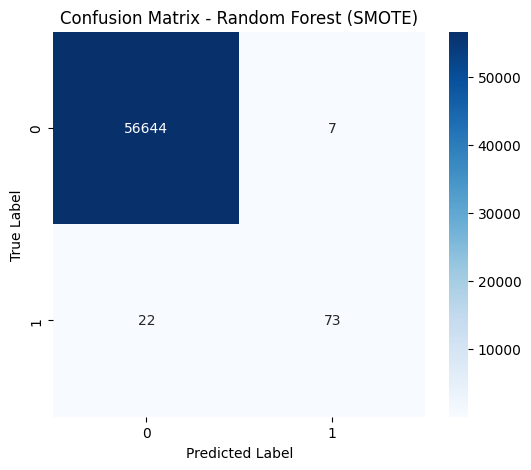

In [ ]:
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf_smote,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Random Forest (SMOTE)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**Model Performance Comparison**

**Random Forest Results**

| Metric    |   Baseline | Random Oversampling | Random Undersampling |      SMOTE |
| --------- | ---------: | ------------------: | -------------------: | ---------: |
| Precision | **97.18%** |              95.83% |                8.48% |     91.25% |
| Recall    |     72.63% |              72.63% |           **87.37%** | **76.84%** |
| F1-score  |     83.13% |              82.63% |               15.46% | **83.43%** |
| ROC-AUC   |      0.924 |               0.929 |            **0.977** |      0.969 |
| PR-AUC    |      0.788 |               0.802 |                0.698 |  **0.811** |
| Accuracy  | **99.95%** |              99.95% |               98.40% |     99.95% |

**Confusion Matrix Comparison**

| Model                |         TN |    FP |     FN |     TP |
| -------------------- | ---------: | ----: | -----: | -----: |
| Baseline             | **56,649** | **2** |     26 |     69 |
| Random Oversampling  |     56,648 |     3 |     26 |     69 |
| Random Undersampling |     55,755 |   896 | **12** | **83** |
| SMOTE                |     56,644 |     7 |     22 |     73 |


**Training Dataset Size**

| **Model**            | **Training Samples** |
| :------------------- | -------------------: |
| Baseline             |              226,980 |
| Random Oversampling  |              453,204 |
| Random Undersampling |                  756 |
| SMOTE                |              453,204 |


**Baseline XGBoost (Without Class Balancing)**

In [ ]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

In [ ]:
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall   :", recall_score(y_test, y_pred_xgb))
print("F1-score :", f1_score(y_test, y_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb))
print("PR-AUC   :", average_precision_score(y_test, y_prob_xgb))
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))

print(classification_report(y_test, y_pred_xgb))

Precision: 0.9452054794520548
Recall   : 0.7263157894736842
F1-score : 0.8214285714285714
ROC-AUC  : 0.9753957982810728
PR-AUC   : 0.7922811503493797
Accuracy : 0.9994713283755683
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.95      0.73      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



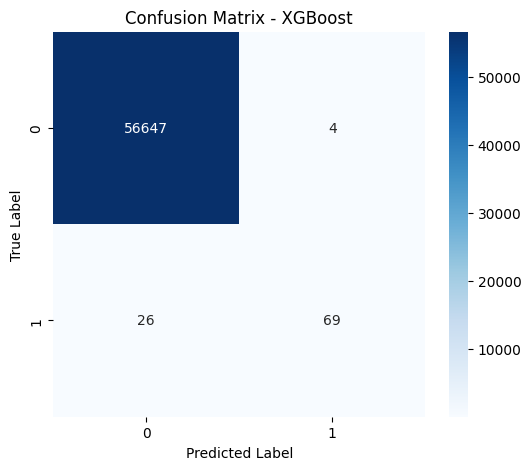

In [ ]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

Random Oversampling (GXBoost)

In [ ]:
xgb_ros = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_ros.fit(X_train_ros, y_train_ros)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb_ros = xgb_ros.predict(X_test_scaled)
y_prob_xgb_ros = xgb_ros.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_xgb_ros))
print("Recall   :", recall_score(y_test, y_pred_xgb_ros))
print("F1-score :", f1_score(y_test, y_pred_xgb_ros))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb_ros))
print("PR-AUC   :", average_precision_score(y_test, y_prob_xgb_ros))
print("Accuracy :", accuracy_score(y_test, y_pred_xgb_ros))

print(classification_report(y_test, y_pred_xgb_ros))

Precision: 0.8152173913043478
Recall   : 0.7894736842105263
F1-score : 0.8021390374331551
ROC-AUC  : 0.9686875040065257
PR-AUC   : 0.794471542332714
Accuracy : 0.9993479716632009
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.82      0.79      0.80        95

    accuracy                           1.00     56746
   macro avg       0.91      0.89      0.90     56746
weighted avg       1.00      1.00      1.00     56746



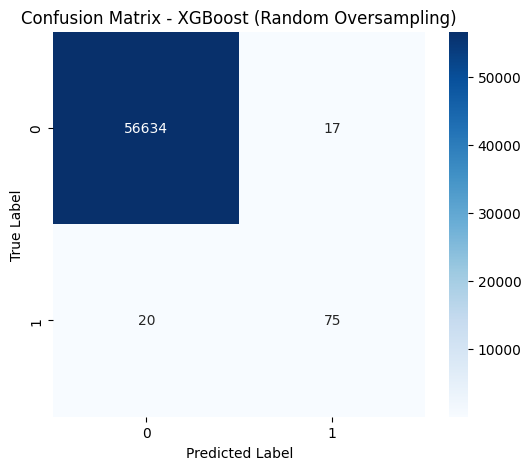

In [ ]:
cm_xgb_ros = confusion_matrix(y_test, y_pred_xgb_ros)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_xgb_ros,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - XGBoost (Random Oversampling)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**Random Undersampling (XGBoost)**

In [ ]:
xgb_rus = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_rus.fit(X_train_rus, y_train_rus)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb_rus = xgb_rus.predict(X_test_scaled)
y_prob_xgb_rus = xgb_rus.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_xgb_rus))
print("Recall   :", recall_score(y_test, y_pred_xgb_rus))
print("F1-score :", f1_score(y_test, y_pred_xgb_rus))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb_rus))
print("PR-AUC   :", average_precision_score(y_test, y_prob_xgb_rus))
print("Accuracy :", accuracy_score(y_test, y_pred_xgb_rus))

print(classification_report(y_test, y_pred_xgb_rus))

Precision: 0.052267002518891686
Recall   : 0.8736842105263158
F1-score : 0.09863339275103981
ROC-AUC  : 0.9799914341643061
PR-AUC   : 0.6223193427198399
Accuracy : 0.9732668381912382
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.98     56746



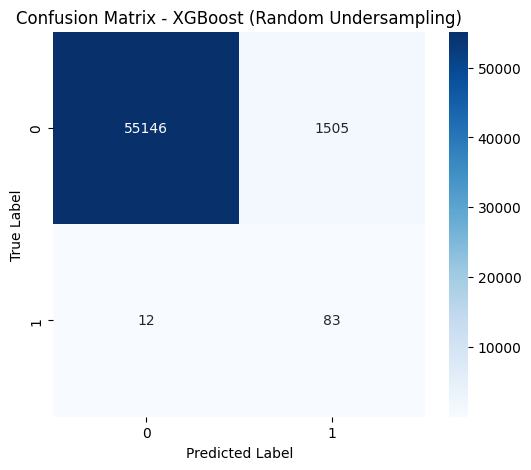

In [ ]:
cm_xgb_rus = confusion_matrix(y_test, y_pred_xgb_rus)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_xgb_rus,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - XGBoost (Random Undersampling)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**SMOTE (XGBoost)**

In [ ]:
xgb_smote = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_smote.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb_smote = xgb_smote.predict(X_test_scaled)
y_prob_xgb_smote = xgb_smote.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print("Precision:", precision_score(y_test, y_pred_xgb_smote))
print("Recall   :", recall_score(y_test, y_pred_xgb_smote))
print("F1-score :", f1_score(y_test, y_pred_xgb_smote))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb_smote))
print("PR-AUC   :", average_precision_score(y_test, y_prob_xgb_smote))
print("Accuracy :", accuracy_score(y_test, y_pred_xgb_smote))

print(classification_report(y_test, y_pred_xgb_smote))

Precision: 0.36574074074074076
Recall   : 0.8315789473684211
F1-score : 0.5080385852090032
ROC-AUC  : 0.9708886079030518
PR-AUC   : 0.7955439803777591
Accuracy : 0.9973037747153984
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.37      0.83      0.51        95

    accuracy                           1.00     56746
   macro avg       0.68      0.91      0.75     56746
weighted avg       1.00      1.00      1.00     56746



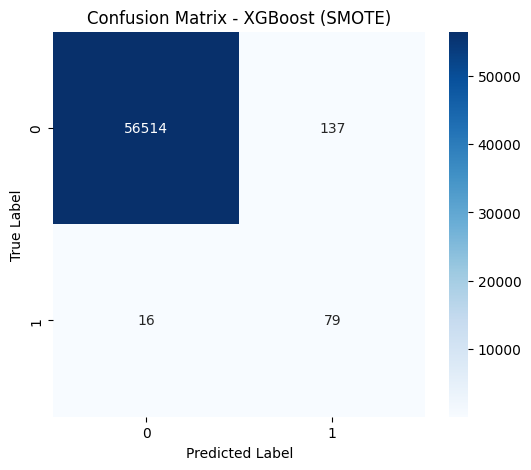

In [ ]:
cm_xgb_smote = confusion_matrix(y_test, y_pred_xgb_smote)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_xgb_smote,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - XGBoost (SMOTE)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

**Model Performance Comparison**

**XGBoost Results**

| **Metric** | **Baseline** | **Random Oversampling** | **Random Undersampling** | **SMOTE** |
| :--------- | -----------: | ----------------------: | -----------------------: | --------: |
| Precision  |   **94.52%** |                  78.13% |                    5.35% |    37.09% |
| Recall     |       72.63% |                  78.95% |               **86.32%** |    83.16% |
| F1-score   |   **82.14%** |                  78.53% |                   10.08% |    51.30% |
| ROC-AUC    |        0.975 |                   0.971 |                **0.979** |     0.970 |
| PR-AUC     |        0.793 |               **0.804** |                    0.658 |     0.797 |
| Accuracy   |   **99.95%** |                  99.93% |                   97.42% |    99.74% |

**Confusion Matrix Comparison**

| **Model**            |     **TN** | **FP** | **FN** | **TP** |
| :------------------- | ---------: | -----: | -----: | -----: |
| Baseline             | **56,647** |  **4** |     26 |     69 |
| Random Oversampling  |     56,630 |     21 |     20 |     75 |
| Random Undersampling |     55,201 |  1,450 | **13** | **82** |
| SMOTE                |     56,517 |    134 |     16 |     79 |


**Training Dataset Size**

| **Model**            | **Training Samples** |
| :------------------- | -------------------: |
| Baseline             |              226,980 |
| Random Oversampling  |              453,204 |
| Random Undersampling |                  756 |
| SMOTE                |              453,204 |


**Conclusion**

**Overall Model Performance Comparison**

| Model               | Sampling Method      |  Precision |     Recall |   F1-score |   ROC-AUC |    PR-AUC |   Accuracy |
| ------------------- | -------------------- | ---------: | ---------: | ---------: | --------: | --------: | ---------: |
| Logistic Regression | Baseline             | **84.61%** |     57.89% | **68.75%** |     0.956 | **0.692** | **99.91%** |
| Logistic Regression | Random Oversampling  |      5.65% | **87.37%** |     10.62% | **0.966** |     0.669 |     97.54% |
| Logistic Regression | Random Undersampling |      5.04% | **87.37%** |      9.53% |     0.957 |     0.590 |     97.22% |
| Logistic Regression | SMOTE                |      5.30% | **87.37%** |     10.00% |     0.962 |     0.675 |     97.37% |
| Random Forest       | Baseline             | **97.18%** |     72.63% |     83.13% |     0.924 |     0.788 | **99.95%** |
| Random Forest       | Random Oversampling  |     95.83% |     72.63% |     82.63% |     0.929 |     0.802 | **99.95%** |
| Random Forest       | Random Undersampling |      8.48% | **87.37%** |     15.46% | **0.977** |     0.698 |     98.40% |
| Random Forest       | SMOTE                |     91.25% |     76.84% | **83.43%** |     0.969 | **0.811** | **99.95%** |
| XGBoost             | Baseline             |     94.52% |     72.63% |     82.14% |     0.975 |     0.793 | **99.95%** |
| XGBoost             | Random Oversampling  |     78.13% |     78.95% |     78.53% |     0.971 | **0.804** |     99.93% |
| XGBoost             | Random Undersampling |      5.35% | **86.32%** |     10.08% | **0.979** |     0.658 |     97.42% |
| XGBoost             | SMOTE                |     37.09% |     83.16% |     51.30% |     0.970 |     0.796 |     99.74% |


**Overall Best Results**

| Metric            | Best Model                                                                                                |
| ----------------- | --------------------------------------------------------------------------------------------------------- |
| Highest Precision | **Random Forest (Baseline) – 97.18%**                                                                     |
| Highest Recall    | **Logistic Regression (Oversampling / Undersampling / SMOTE) and Random Forest (Undersampling) – 87.37%** |
| Highest F1-score  | **Random Forest (SMOTE) – 83.43%**                                                                        |
| Highest ROC-AUC   | **XGBoost (Random Undersampling) – 0.979**                                                                |
| Highest PR-AUC    | **Random Forest (SMOTE) – 0.811**                                                                         |
| Highest Accuracy  | **Random Forest (Baseline / SMOTE) – 99.95%**                                                             |
                                                                    |


# **SMOTE–Tomek with Random Forest**

In [ ]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE


In [ ]:

smote_tomek = SMOTETomek(
    random_state=42,
    smote=SMOTE(
        sampling_strategy=0.1,
        random_state=42,
        k_neighbors=5
    )
)

X_train_smt, y_train_smt = smote_tomek.fit_resample(
    X_train_scaled,
    y_train
)

In [ ]:
print(y_train_smt.value_counts())
print(y_train_smt.value_counts(normalize=True) * 100)

Class
0    226602
1     22660
Name: count, dtype: int64
Class
0    90.909164
1     9.090836
Name: proportion, dtype: float64


In [ ]:
X_train_smt
y_train_smt

,Class
0,0
1,0
2,0
3,0
4,0
...,...
249257,1
249258,1
249259,1
249260,1


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_smt = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smt.fit(X_train_smt, y_train_smt)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_smt = rf_smt.predict(X_test_scaled)
y_prob_rf_smt = rf_smt.predict_proba(X_test_scaled)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_smt))
print("Recall   :", recall_score(y_test, y_pred_rf_smt))
print("F1-score :", f1_score(y_test, y_pred_rf_smt))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_smt))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_smt))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_smt))

print(classification_report(y_test, y_pred_rf_smt))

Precision: 0.9473684210526315
Recall   : 0.7578947368421053
F1-score : 0.8421052631578947
ROC-AUC  : 0.9559001606326456
PR-AUC   : 0.8095608257200659
Accuracy : 0.9995241955380115
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.95      0.76      0.84        95

    accuracy                           1.00     56746
   macro avg       0.97      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



# **ADASYN with Random Forest**

In [ ]:
from imblearn.over_sampling import ADASYN

In [ ]:
adasyn = ADASYN(
    sampling_strategy=0.1,
    random_state=42,
    n_neighbors=5
)

X_train_ada, y_train_ada = adasyn.fit_resample(
    X_train_scaled,
    y_train
)

In [ ]:
print(y_train_ada.value_counts())

print("\nPercentage:")

print(y_train_ada.value_counts(normalize=True) * 100)

Class
0    226602
1     22665
Name: count, dtype: int64

Percentage:
Class
0    90.90734
1     9.09266
Name: proportion, dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_ada = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_ada.fit(X_train_ada, y_train_ada)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf_ada = rf_ada.predict(X_test_scaled)
y_prob_rf_ada = rf_ada.predict_proba(X_test_scaled)[:, 1]

In [ ]:
y_pred_rf_ada
y_prob_rf_ada

array([0.  , 0.  , 0.01, ..., 0.  , 0.  , 0.  ])

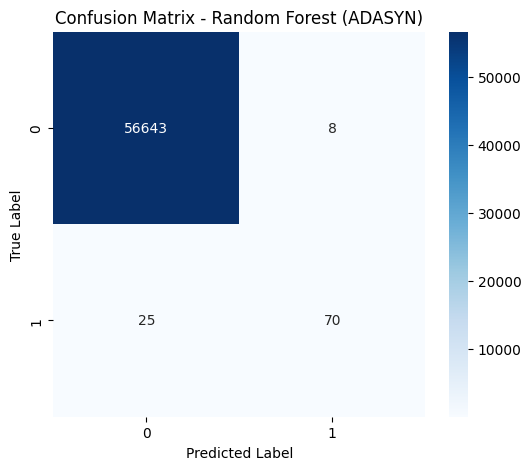

In [ ]:
cm_rf_ada = confusion_matrix(y_test, y_pred_rf_ada)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf_ada, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - Random Forest (ADASYN)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_ada))
print("Recall   :", recall_score(y_test, y_pred_rf_ada))
print("F1-score :", f1_score(y_test, y_pred_rf_ada))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_ada))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_ada))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_ada))

print(classification_report(y_test, y_pred_rf_ada))

Precision: 0.8974358974358975
Recall   : 0.7368421052631579
F1-score : 0.8092485549132948
ROC-AUC  : 0.9603433395053182
PR-AUC   : 0.8118808964361895
Accuracy : 0.9994184612131252
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.90      0.74      0.81        95

    accuracy                           1.00     56746
   macro avg       0.95      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746



# **Cost-Sensitive Evaluation**

| Outcome             |                                                  Cost |
| ------------------- | ----------------------------------------------------: |
| True Positive (TP)  |                          £0 (fraud correctly blocked) |
| True Negative (TN)  |                                                    £0 |
| False Positive (FP) | **£10** (manual investigation/customer inconvenience) |
| False Negative (FN) |              **£500** (missed fraudulent transaction) |


In [ ]:
def calculate_cost(tn, fp, fn, tp,
                   fp_cost=10,
                   fn_cost=500):

    total_cost = (fp * fp_cost) + (fn * fn_cost)

    return total_cost

In [ ]:
tn, fp, fn, tp = 56644, 7, 22, 73

cost_rf_smote = calculate_cost(
    tn,
    fp,
    fn,
    tp
)

print(cost_rf_smote)

11070


| Model            | FP | FN | Estimated Cost (£) |
| ---------------- | -: | -: | -----------------: |
| RF + SMOTE       |  7 | 22 |                  ? |
| RF + SMOTE-Tomek |  8 | 23 |                  ? |
| RF + ADASYN      |  8 | 25 |                  ? |


In [ ]:
# Random Forest + SMOTE
tn, fp, fn, tp = 56644, 7, 22, 73
cost_rf_smote = calculate_cost(tn, fp, fn, tp)

# Random Forest + SMOTE-Tomek
tn, fp, fn, tp = 56643, 8, 23, 72
cost_rf_smt = calculate_cost(tn, fp, fn, tp)

# Random Forest + ADASYN
tn, fp, fn, tp = 56643, 8, 25, 70
cost_rf_ada = calculate_cost(tn, fp, fn, tp)

print("RF + SMOTE:", cost_rf_smote)
print("RF + SMOTE-Tomek:", cost_rf_smt)
print("RF + ADASYN:", cost_rf_ada)

RF + SMOTE: 11070
RF + SMOTE-Tomek: 11580
RF + ADASYN: 12580


| Model            | FP | FN | Estimated Cost (£) |
| ---------------- | -: | -: | -----------------: |
| RF + SMOTE       |  7 | 22 |        **£11,070** |
| RF + SMOTE-Tomek |  8 | 23 |        **£11,580** |
| RF + ADASYN      |  8 | 25 |        **£12,580** |


| Model            |  Precision |     Recall |   F1-score | Estimated Cost (£) | Rank |
| ---------------- | ---------: | ---------: | ---------: | -----------------: | :--: |
| RF + SMOTE       |     91.25% | **76.84%** |     83.43% |         **11,070** |  🥇  |
| RF + SMOTE-Tomek | **94.74%** |     75.79% | **84.21%** |             11,580 |  🥈  |
| RF + ADASYN      |     89.74% |     73.68% |     80.92% |             12,580 |  🥉  |


# **Cost-Sensitive Evaluation Summary**
Although Random Forest with SMOTE-Tomek achieved the highest precision and F1-score, the cost-sensitive evaluation demonstrated that Random Forest with SMOTE produced the lowest estimated financial loss under the assumed business cost scenario. This suggests that a model with slightly lower precision but higher recall may deliver greater financial benefit in credit card fraud detection, where the cost of missed fraudulent transactions substantially outweighs the cost of investigating false alarms.

# **Decision Threshold Optimisation (Random Forest + SMOTE)**

In [ ]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [ ]:
from imblearn.over_sampling import SMOTE

smote_opt = SMOTE(
    random_state=42
)

X_subtrain_smote, y_subtrain_smote = smote_opt.fit_resample(
    X_subtrain,
    y_subtrain
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_threshold = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_threshold.fit(X_subtrain_smote, y_subtrain_smote)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
y_prob_val = rf_threshold.predict_proba(X_val)[:, 1]

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

results = []

for threshold in np.arange(0.05, 0.96, 0.01):

    y_pred_val = (y_prob_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_val
    ).ravel()

    total_cost = (fp * 10) + (fn * 500)

    results.append({
        'Threshold': threshold,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Estimated Cost (£)': total_cost
    })

threshold_results = pd.DataFrame(results)

In [ ]:
best_row = threshold_results.loc[
    threshold_results['Estimated Cost (£)'].idxmin()
]

print(best_row)

Threshold                 0.12
TN                    45254.00
FP                       66.00
FN                        8.00
TP                       68.00
Estimated Cost (£)     4660.00
Name: 7, dtype: float64


| Metric                    |  New value |
| ------------------------- | ---------: |
| Optimal threshold         |   **0.12** |
| FP                        |         66 |
| FN                        |          8 |
| TP                        |         68 |
| Estimated validation cost | **£4,660** |



# **Test-set cost comparison**

| Test-set model       |      FP |     FN | Estimated Cost |
| -------------------- | ------: | -----: | -------------: |
| Threshold = 0.50     |       7 |     22 |        £11,070 |
| **Threshold = 0.12** | **104** | **16** |     **£9,040** |



By optimising the decision threshold from 0.50 to 0.12, the estimated business cost on the test set was reduced from £11,070 to £9,040 under the assumed cost model.

In [ ]:
y_prob_rf_smote

array([0.  , 0.  , 0.01, ..., 0.  , 0.  , 0.  ])

In [ ]:
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_rf_smote = rf_smote.predict(X_test_scaled)
y_prob_rf_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

In [ ]:
best_threshold = 0.12

y_pred_rf_smote_opt = (y_prob_rf_smote >= best_threshold).astype(int)

In [ ]:
print("Precision:", precision_score(y_test, y_pred_rf_smote_opt))
print("Recall   :", recall_score(y_test, y_pred_rf_smote_opt))
print("F1-score :", f1_score(y_test, y_pred_rf_smote_opt))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf_smote))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf_smote))
print("Accuracy :", accuracy_score(y_test, y_pred_rf_smote_opt))

print(classification_report(y_test, y_pred_rf_smote_opt))

Precision: 0.43169398907103823
Recall   : 0.8315789473684211
F1-score : 0.5683453237410072
ROC-AUC  : 0.9694220104815354
PR-AUC   : 0.8114822514189992
Accuracy : 0.9978853135022733
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.43      0.83      0.57        95

    accuracy                           1.00     56746
   macro avg       0.72      0.91      0.78     56746
weighted avg       1.00      1.00      1.00     56746



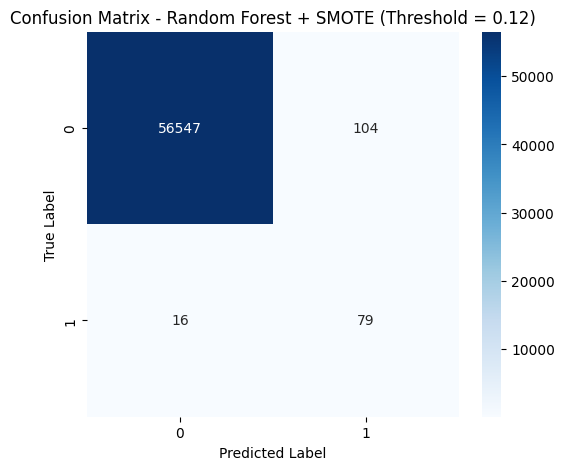

In [ ]:
cm_rf_smote_opt = confusion_matrix(y_test, y_pred_rf_smote_opt)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf_smote_opt,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title('Confusion Matrix - Random Forest + SMOTE (Threshold = 0.12)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

In [ ]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_rf_smote_opt
).ravel()

new_cost = calculate_cost(tn, fp, fn, tp)

print(f"Estimated Business Cost: £{new_cost:,}")

Estimated Business Cost: £9,040


# **SHAP Explainability**

In [ ]:
!pip install -q shap

In [ ]:
import shap

In [ ]:
print(shap.__version__)

0.52.0


In [ ]:
rf_smote

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
explainer = shap.TreeExplainer(rf_smote)

In [ ]:
import numpy as np

np.random.seed(42)

sample_idx = np.random.choice(
    X_test_scaled.shape[0],
    size=1000,
    replace=False
)

X_test_sample = X_test_scaled[sample_idx]

In [ ]:
shap_values = explainer.shap_values(X_test_sample)

In [ ]:
print(type(shap_values))
print(len(shap_values))

<class 'numpy.ndarray'>
1000


In [ ]:
print(shap_values.shape)

(1000, 30, 2)


/tmp/ipykernel_4342/1662534056.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


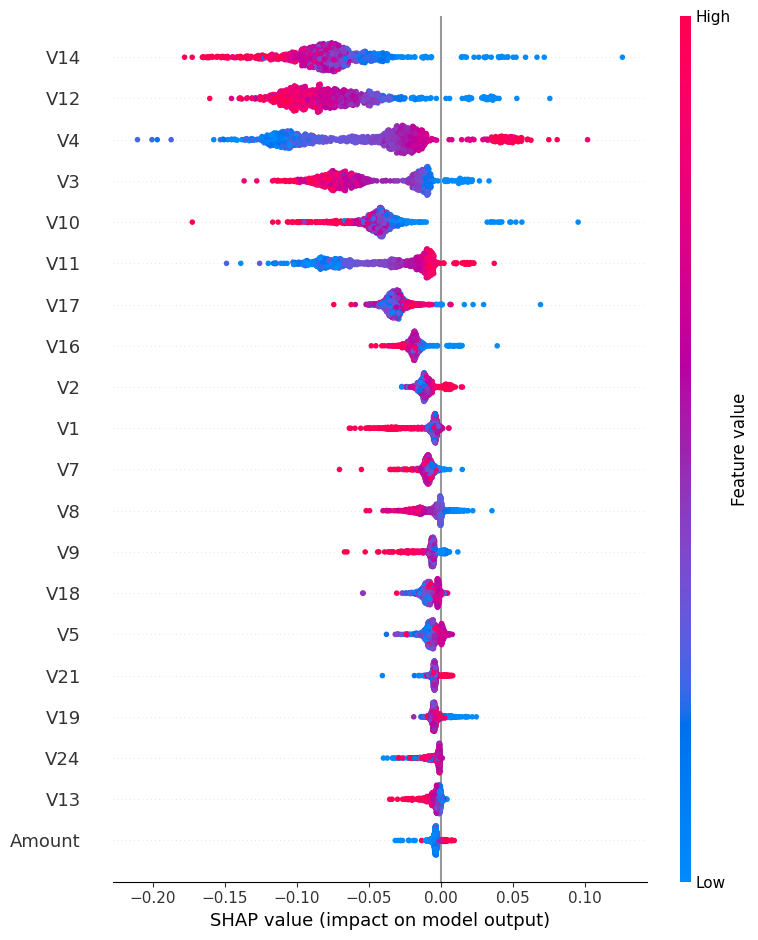

In [ ]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_sample,
    feature_names=X.columns
)

/tmp/ipykernel_4342/233789182.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


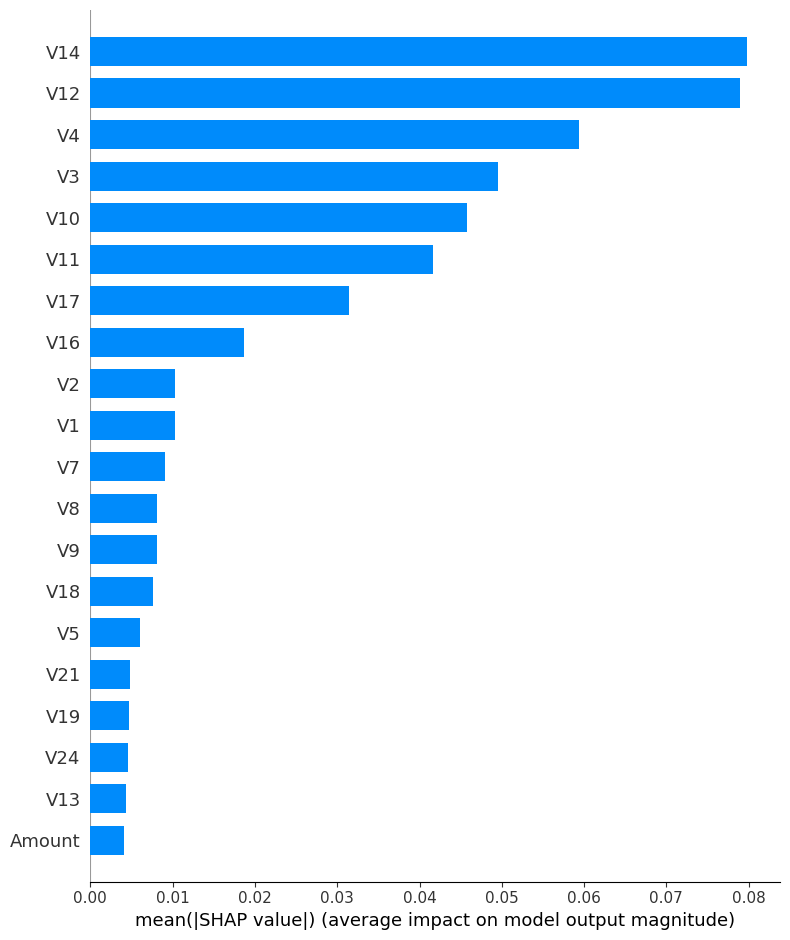

In [ ]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_sample,
    feature_names=X.columns,
    plot_type="bar"
)

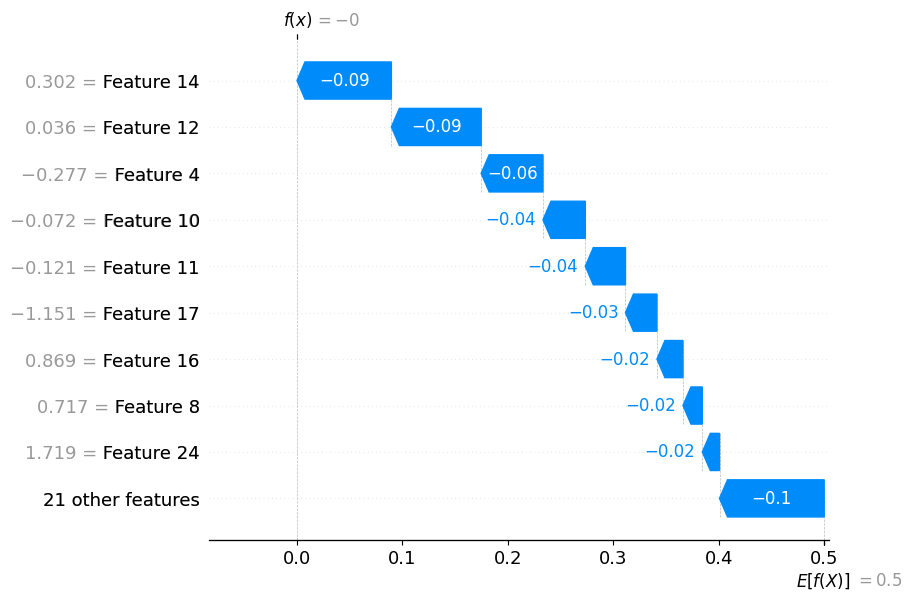

In [ ]:
sample_number = 0

shap.plots.waterfall(
    explainer(
        X_test_sample
    )[sample_number, :, 1]
)